---
title: Week 3 Challenge 3 KEY
subtitle: DS 2023 | Communicating with Data
---

## Overview

In today's challenge, you will apply what you have learned about how to use some of the more advanced display options for Pandas' pie charts and line graphs.

Use the relevant notebooks as your guide.

Work in groups to perform the tasks.

When finished, submit a URL to this notebook in your GitHub repo to today's participation assignment.

## The data set

Today's data source contains information about music from Spotify.

It's a modified version of [the one you can find on Kaggle](https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset).

Here is data dictionary for the ten measurement variables in the dataset:

| Metric | Definition | Scale / Range |
|---|---|---|
| beats (Tempo) | The overall estimated speed or pace of a track. | Beats Per Minute (BPM) |
| energy | A perceptual measure of intensity and activity (e.g., fast, loud, noisy). | 0.0 to 1.0 (High is energetic) |
| danceability | How suitable a track is for dancing based on tempo, rhythm stability, beat strength, and regularity. | 0.0 to 1.0 (High is more danceable) |
| loudness | The overall volume of a track averaged across the entire recording. | -60 to 0 decibels (dB) |
| liveness | Detects the presence of an audience in the recording (e.g., live concert tracks). | 0.0 to 1.0 (Above 0.8 is strongly live) |
| valence | The musical positiveness conveyed by a track (high valence sounds happy/cheerful; low valence sounds sad/angry). | 0.0 to 1.0 |
| length (Duration) | The total duration or runtime of the song. | Typically seconds or milliseconds |
| acousticness | A confidence measure of whether the track uses non-electronic, acoustic instruments. | 0.0 to 1.0 (1.0 is purely acoustic) |
| speechiness | Detects the presence of spoken words. Higher values represent talk shows, audiobooks, or rap music. | 0.0 to 1.0 (Above 0.66 is mostly speech) |
| popularity | A dynamic score calculated by Spotify based on total plays and how recent those plays are. | 0 to 100 (100 is a top global hit) |

## Set Up

We import the standard set of libraries.

In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

We import the data from the web.

We also make a few modifications. 

In [157]:
data_source = "https://virginia.box.com/shared/static/it00dmpk006n0iptijzvjg1qmlyscmlo.csv"
spotify = pd.read_csv(data_source)

# A couple of quick mods ...
spotify = spotify.set_index('song_id')
spotify['decade'] = spotify['decade'] * 10
spotify = spotify.rename(columns={'group':'genre'})

spotify.info()
spotify.head()

<class 'pandas.DataFrame'>
Index: 1710 entries, 0 to 1984
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   title         1710 non-null   str  
 1   artist        1710 non-null   str  
 2   top           1710 non-null   str  
 3   year          1710 non-null   int64
 4   beats         1710 non-null   int64
 5   energy        1710 non-null   int64
 6   danceability  1710 non-null   int64
 7   loudness      1710 non-null   int64
 8   liveness      1710 non-null   int64
 9   valence       1710 non-null   int64
 10  length        1710 non-null   int64
 11  acousticness  1710 non-null   int64
 12  speechiness   1710 non-null   int64
 13  popularity    1710 non-null   int64
 14  genre         1710 non-null   str  
 15  decade        1710 non-null   int64
dtypes: int64(12), str(4)
memory usage: 227.1 KB


,title,artist,top,year,beats,energy,danceability,loudness,liveness,valence,length,acousticness,speechiness,popularity,genre,decade
song_id,,,,,,,,,,,,,,,,
0,Sunrise,Norah Jones,adult standards,2004,157,30,53,-14,11,68,201,94,3,71,standards,2000
1,Black Night,Deep Purple,album rock,2000,135,79,50,-11,17,81,207,17,7,39,rock,2000
2,Clint Eastwood,Gorillaz,alternative hip hop,2001,168,69,66,-9,7,52,341,2,17,69,hip,2000
3,The Pretender,Foo Fighters,alternative metal,2007,173,96,43,-4,3,37,269,0,4,76,metal,2000
4,Waitin' On A Sunny Day,Bruce Springsteen,classic rock,2002,106,82,58,-5,10,87,256,1,3,59,rock,2000


## Tasks

### Task 1

Create pie chart the shows the value counts for each genre.

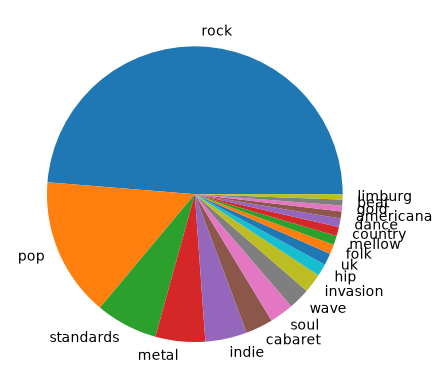

In [81]:
spotify.value_counts('genre').plot.pie()
plt.show()

### Task 2

Recreate the pie chart from the previous task but pop out the wedge that represents the genre `pop`.

Hint: To do this, you need to pass a tuple to the `explode` argument. You can generate that tuple as follows:

```python
explode_tuple = [0 for i in range(n_genres)]
```

You need to compute `n_genres` (the number of genres in the domain) first.

Also, once you have the tuple, find the offset of the genre `pop` and set its value to $.1$ in the list.

To get the offset, look at the index of the series returned by the value counts operation and see where `pop` is there.


In [160]:
genre_counts = spotify.value_counts('genre')
explode_list = [0 for i in range(len(genre_counts))]
explode_list[1] = .1
explode_list

[0, 0.1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

In [166]:
genre_counts

genre
rock         833
pop          260
standards    116
metal         93
indie         78
cabaret       51
soul          45
wave          40
invasion      36
hip           23
uk            22
folk          18
mellow        17
country       17
dance         16
americana     13
gold          11
beat          11
limburg       10
Name: count, dtype: int64

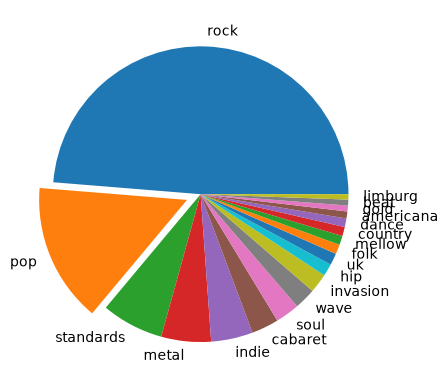

In [161]:
genre_counts.plot.pie(explode=explode_list)
plt.show()

### Task 3

Recreate the task from the previous task but rotate it so that the start angle is $90\degree$.

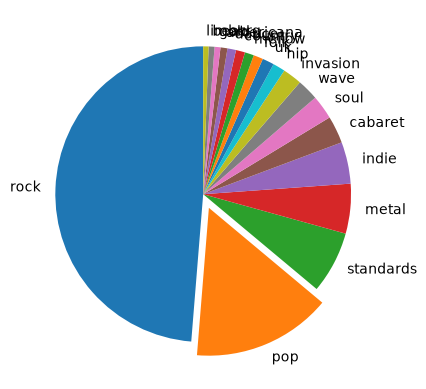

In [162]:
genre_counts.plot.pie(explode=explode_list, startangle=90)
plt.show()

### Task 4

Create a bar chart of the value counts of observations per decade.

Make sure the x axis shows the decade in proper order.

You _don't_ need to convert the decade column to `datetime` to do this.

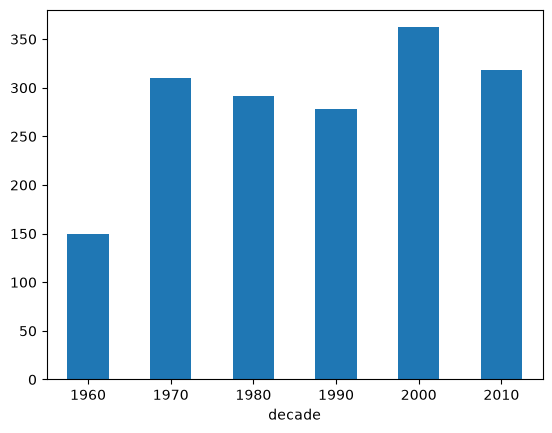

In [85]:
spotify.value_counts('decade').sort_index().plot.bar(rot=0)
plt.show()

### Task 5

Create a pair of line graphs showing how `accousticness` and `loudness` have changed over the years. Represent these line graphs on the same plot, so that you can see how they change relative to each other.

More specifically, your graph should meet the following requiremens:

1. It displays the domain of `year` on the x axis.
2. It displays the domain of `accousticness` on the left y axis.
3. It displays the domain of `loudness` on the right y axis.
4. It displays the values of `acousticness` as a red line.
5. It displays the values of `loudness` as a blue line.
6. It has a figure size of $10$ by $5$ (width by height).
7. It has variable labels on the left and right y axis.

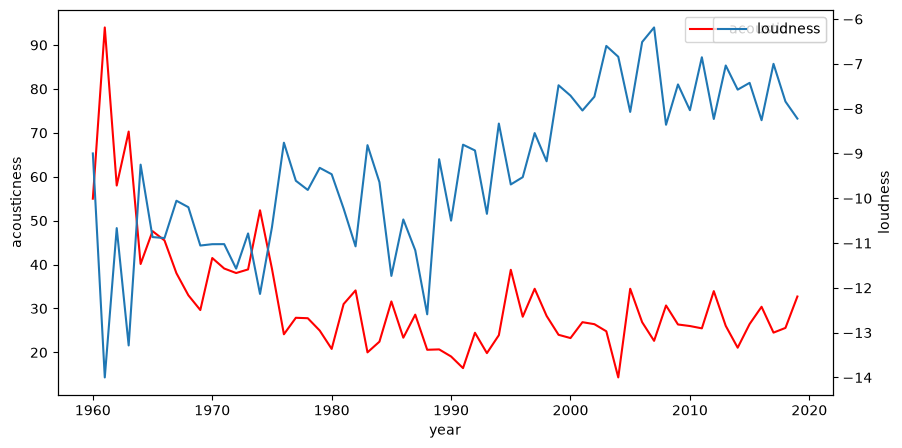

In [171]:
ax = year['acousticness'].plot.line(color='red', legend=True, figsize=(10,5))
ax2 = plt.twinx(ax)
year['loudness'].plot.line(ax=ax2, legend=True)
ax.set_ylabel('acousticness')
ax2.set_ylabel('loudness')
plt.show()

Here is a way to fix the overlapping legends.

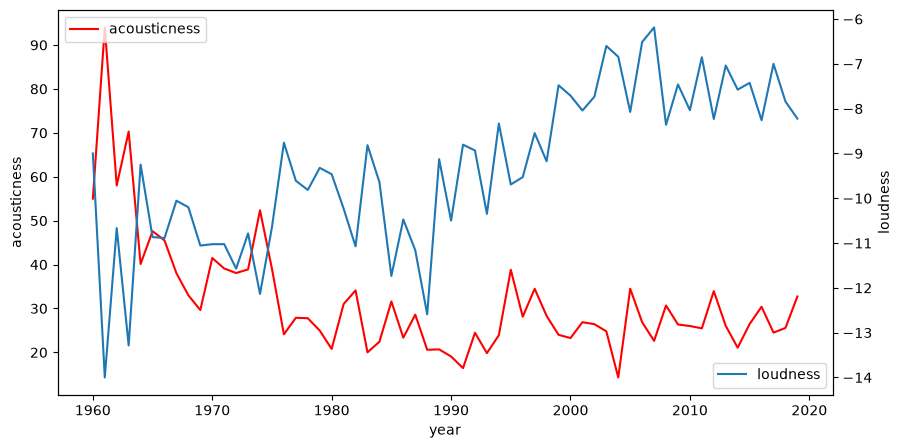

In [172]:
ax = year['acousticness'].plot.line(color='red', legend=True, figsize=(10,5))
ax2 = plt.twinx(ax)
year['loudness'].plot.line(ax=ax2, legend=True)

# Legend fix 
ax.legend(loc='upper left')
ax2.legend(loc='lower right')

ax.set_ylabel('acousticness')
ax2.set_ylabel('loudness')
plt.show()

Here is another, slightly more complicated way.

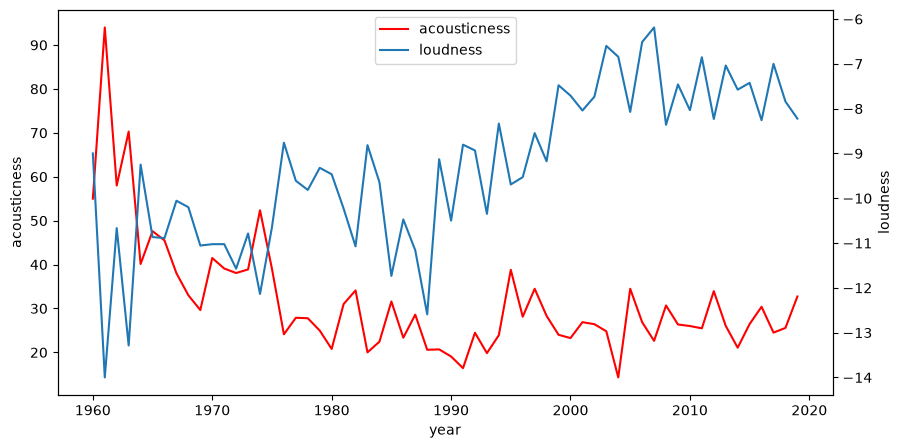

In [176]:
ax = year['acousticness'].plot.line(color='red', figsize=(10, 5))
ax2 = ax.twinx()
year['loudness'].plot.line(ax=ax2)

ax.set_ylabel('acousticness')
ax2.set_ylabel('loudness')

# Gather handles and labels from both axes and make one legend
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax2.legend(h1 + h2, l1 + l2, loc='upper center')

plt.show()